# Routing the commutes with the TravelWhiz timetables, London

04.2 routed the London commutes with two transit sources: the Bus Open Data Service
aggregate cropped by transitio, and the gb-transit rail and TfL file. This notebook
repeats the same routing with a different transit source, the GB GTFS feeds curated by
TravelWhiz (`github.com/travelwhiz-ltd/GB-Bus-Train-Metro-GTFS`), and compares the
two at the end. Everything else is kept as in 04.2: the same grid, the same routing
points, the same street network, the same departure, the same cafein settings. Only
the timetables change, so any difference in the transit times comes from the feeds.

| Step | What we do |
|---|---|
| 1. Inputs | The input files, now with the two TravelWhiz feeds |
| 2. Test trips | The ten strongest commuting pairs, as in 04.2 |
| 3. Routing points | The street network and the snapped, population-weighted points, with the code of 04.2 |
| 4. Timetables | The two TravelWhiz feeds: what is inside, and what runs on the departure day |
| 5. Routing | cafein network from the TravelWhiz feeds, and the test trips by car, bicycle and transit |
| 6. Whole city | The three modes for every pair of routing points, joined to the commuting flows |
| 7. Per cell | Median commuting time of each cell's residents, by mode |
| 8. Comparison | Transit times of this notebook against those of 04.2, trip by trip and cell by cell |

In [1]:
import json
import time
import urllib.request
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from shapely.ops import nearest_points

from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix
from cafein._streaming import read_shards

## Parameters

The same values as 04.2, except the transit block. TravelWhiz rebuilds its feeds every
night and overwrites them at a fixed URL, without versioned releases. The copies used
here were generated on the night of 2026-11-02 and are kept on scratch with that date
in the file name; if a file is missing the notebook downloads the current one, which is
then a different night's build.

In [2]:
CITY = "London"
CITY_ID = "187_GB_London"

DATA = Path("/scratch/project_2010423/data")
OSM_PBF = DATA / "osm" / "greater-london-latest.osm.pbf"
OD_FOLDER = DATA / "worldcommuting-od" / CITY_ID
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting") / CITY.lower()

TEST_PAIRS = 10   # strongest OD pairs used as test trips

# Street network artifact built in 04.2 and saved in networks/.
STREET_ARTIFACT = Path("networks/london-streets.cafein")
COUNTRY = "GB"    # legal default speed limits for ways without a maxspeed tag (car routing)

# Routing points as in 04.2: population-weighted centres, snapped to a street inside the cell.
POINT_METHOD = "population"
WORLDPOP_RASTER = DATA / "worldpop-2020-1km" / "gbr_ppp_2020_1km_Aggregated_UNadj.tif"
SNAP_DISTANCE_M = 1000

# Transit timetables (step 4): the TravelWhiz feeds.
TRANSIT_SOURCE = "travelwhiz"
TRAVELWHIZ_DATE = "2026-11-02"   # night the feeds were generated
TRAVELWHIZ_URL = "https://storage.travelwhiz.app/generated-gtfs/"
TRAVELWHIZ_FEEDS = {
    "uk-busmetro-SE-LONDON": "buses, Underground, DLR, trams, cable car and river services of London and the South East",
    "gb-nationalrail": "National Rail, including the Overground lines and the Elizabeth line",
}
GTFS_DIR = DATA / "gtfs" / CITY.lower()
GTFS_FILES = [GTFS_DIR / f"travelwhiz-{name}-{TRAVELWHIZ_DATE}.zip" for name in TRAVELWHIZ_FEEDS]

# Routing (step 5): the same departure as 04.2, a normal Tuesday morning at 08:30, inside the
# validity of both feeds (London and South East 2026-10-23 to 2027-05-01, rail 2026-05-17 to 2027-05-15).
DEPARTURE = "2026-11-10 08:30"
MODES = ["car", "bicycle", "transit"]
TRANSIT_ARTIFACT = Path("networks/london-transit-travelwhiz.cafein")
RUN_ROUTING = True

# Results of this notebook, and the 04.2 results they are compared with (step 8).
MATRICES = RESULTS / POINT_METHOD / TRANSIT_SOURCE
MATRICES.mkdir(parents=True, exist_ok=True)
REFERENCE = RESULTS / POINT_METHOD
REFERENCE_ARTIFACT = Path("networks/london-transit.cafein")

## 1. Inputs

What is on disk. The two transit rows are the TravelWhiz feeds.

In [3]:
inputs = pd.DataFrame([
    {"input": "commuting OD grid and matrix", "path": str(OD_FOLDER), "exists": OD_FOLDER.exists(),
     "source": "WorldCommuting-OD repository (04.1)"},
    {"input": "OpenStreetMap extract", "path": str(OSM_PBF), "exists": OSM_PBF.exists(),
     "source": "Geofabrik, Greater London"},
    {"input": "street network", "path": str(STREET_ARTIFACT), "exists": STREET_ARTIFACT.exists(),
     "source": "built in 04.2 from the extract"},
] + [
    {"input": f"GTFS timetable: {description}", "path": str(path), "exists": path.exists(),
     "source": f"TravelWhiz {name}.gtfs.zip, generated {TRAVELWHIZ_DATE}"}
    for (name, description), path in zip(TRAVELWHIZ_FEEDS.items(), GTFS_FILES)
])
inputs

,input,path,exists,source
0,commuting OD grid and matrix,/scratch/project_2010423/data/worldcommuting-o...,True,WorldCommuting-OD repository (04.1)
1,OpenStreetMap extract,/scratch/project_2010423/data/osm/greater-lond...,True,"Geofabrik, Greater London"
2,street network,london-streets.cafein,True,built in 04.2 from the extract
3,"GTFS timetable: buses, Underground, DLR, trams...",/scratch/project_2010423/data/gtfs/london/trav...,True,"TravelWhiz uk-busmetro-SE-LONDON.gtfs.zip, gen..."
4,"GTFS timetable: National Rail, including the O...",/scratch/project_2010423/data/gtfs/london/trav...,True,"TravelWhiz gb-nationalrail.gtfs.zip, generated..."


## 2. Test trips

Read as in 04.2: the grid, the flow matrix, one centre per cell in latitude and
longitude, and the ten strongest pairs as test trips.

In [4]:
regions = gpd.read_file(OD_FOLDER / "CityAndRegionSplit" / "regions.shp")
flows = np.load(OD_FOLDER / "CommutingODFlows" / "generation.npy").astype(float)
assert len(regions) == flows.shape[0]

centres = regions.copy()
centres["geometry"] = regions.geometry.centroid
centres = centres.to_crs("EPSG:4326")[["locations", "geometry"]].rename(columns={"locations": "id"})

origin, destination = np.nonzero(flows)
pairs = pd.DataFrame({"origin": origin, "destination": destination, "flow": flows[origin, destination]})
pairs = pairs.nlargest(TEST_PAIRS, "flow").reset_index(drop=True)
pairs["from_id"] = centres["id"].to_numpy()[pairs["origin"]]
pairs["to_id"] = centres["id"].to_numpy()[pairs["destination"]]

metric = regions.geometry.centroid
dx = metric.x.to_numpy()[pairs["destination"]] - metric.x.to_numpy()[pairs["origin"]]
dy = metric.y.to_numpy()[pairs["destination"]] - metric.y.to_numpy()[pairs["origin"]]
pairs["straight_km"] = np.hypot(dx, dy) / 1000

print(f"{len(centres)} cell centres; {len(pairs)} test trips")
pairs[["from_id", "to_id", "flow", "straight_km"]].round(2)

281 cell centres; 10 test trips


,from_id,to_id,flow,straight_km
0,14-14,11-10,3320.0,12.31
1,6-3,8-9,2918.0,16.11
2,1-8,8-9,2727.0,18.27
3,14-14,12-10,2687.0,10.95
4,6-3,10-6,2626.0,13.01
5,14-14,10-10,2616.0,14.02
6,14-14,10-11,2473.0,12.35
7,6-3,9-8,2460.0,14.95
8,13-4,12-8,2420.0,10.65
9,13-4,11-9,2340.0,13.92


## 3. Routing points

The street network of 04.2 is loaded from its artifact, and the routing points are
rebuilt with the same code: the population-weighted centre of each cell (WorldPop
2020), moved to the nearest street inside the cell, at most `SNAP_DISTANCE_M` away.
The maps of that step are in 04.2; here only the counts are shown, to confirm that
the points are the same.

In [5]:
streets = StreetNetwork.load(STREET_ARTIFACT)
edges = streets.streets_gdf.to_crs(regions.crs)
print(f"vertices {streets.vertex_count:,}, edges {len(edges):,}")

vertices 2,067,386, edges 2,296,703


In [6]:
cells = regions[["locations", "geometry"]].copy()
cells["geometric_centre"] = regions.geometry.centroid

with rasterio.open(WORLDPOP_RASTER) as raster:
    bounds = regions.to_crs(raster.crs).total_bounds
    window = rasterio.windows.from_bounds(*bounds, transform=raster.transform)
    values = raster.read(1, window=window)
    transform = raster.window_transform(window)
    nodata = raster.nodata
rows, cols = np.where(values > 0) if nodata is None else np.where((values > 0) & (values != nodata))
xs, ys = rasterio.transform.xy(transform, rows, cols)
pixels = gpd.GeoDataFrame({"population": values[rows, cols]}, geometry=gpd.points_from_xy(xs, ys), crs=raster.crs).to_crs(regions.crs)

pixels = gpd.sjoin(pixels, cells[["locations", "geometry"]], how="inner", predicate="within")
pixels["wx"] = pixels.geometry.x * pixels["population"]
pixels["wy"] = pixels.geometry.y * pixels["population"]
weighted = pixels.groupby("locations")[["wx", "wy", "population"]].sum()
weighted["x"] = weighted["wx"] / weighted["population"]
weighted["y"] = weighted["wy"] / weighted["population"]

cells = cells.merge(weighted[["x", "y", "population"]], on="locations", how="left")
has_population = cells["population"] > 0
cells["population_centre"] = cells["geometric_centre"]
cells.loc[has_population, "population_centre"] = gpd.points_from_xy(cells.loc[has_population, "x"], cells.loc[has_population, "y"])
cells["centre"] = cells["population_centre"] if POINT_METHOD == "population" else cells["geometric_centre"]

print(f"{len(pixels):,} WorldPop pixels inside the grid; {has_population.sum()} of {len(cells)} cells get a population-weighted centre")

2,956 WorldPop pixels inside the grid; 266 of 281 cells get a population-weighted centre


In [7]:
edges_in_cells = gpd.sjoin(edges[["geometry"]], cells[["locations", "geometry"]], how="inner", predicate="intersects")

snapped = []
for _, cell in cells.iterrows():
    inside = edges_in_cells.loc[edges_in_cells["locations"] == cell["locations"], "geometry"]
    if len(inside) == 0:
        snapped.append({"locations": cell["locations"], "snap_distance_m": np.nan, "snapped": None})
        continue
    streets_inside = inside.intersection(cell["geometry"]).union_all()
    point_on_street = nearest_points(cell["centre"], streets_inside)[1]
    snapped.append({"locations": cell["locations"],
                    "snap_distance_m": cell["centre"].distance(point_on_street),
                    "snapped": point_on_street})
snapped = pd.DataFrame(snapped)

cells = cells.merge(snapped, on="locations")
cells["within_rule"] = cells["snap_distance_m"] <= SNAP_DISTANCE_M

routing_points = gpd.GeoDataFrame(
    {"id": cells.loc[cells["within_rule"], "locations"].to_numpy()},
    geometry=cells.loc[cells["within_rule"], "snapped"].to_numpy(),
    crs=regions.crs,
).to_crs("EPSG:4326")

print(f"{len(cells)} cells; {(~cells['within_rule']).sum()} left without a point under the {SNAP_DISTANCE_M} m rule; "
      f"{len(routing_points)} routing points")
routing_points.head()

281 cells; 2 left without a point under the 1000 m rule; 279 routing points


,id,geometry
0,0-7,POINT (-0.48852 51.46703)
1,0-8,POINT (-0.47696 51.49866)
2,0-9,POINT (-0.47649 51.51627)
3,0-10,POINT (-0.48005 51.53654)
4,0-11,POINT (-0.47257 51.55748)


## 4. Transit timetables

TravelWhiz merges the official UK sources (Traveline TNDS, the Bus Open Data Service,
Transport for London, National Rail, NaPTAN) into GTFS and publishes them nightly
under a CC BY 4.0 licence. Two of its files cover London:

- **London and South East** (`uk-busmetro-SE-LONDON`): buses of London and the
  surrounding region, plus the Underground, DLR, trams, the cable car and river
  services. It is a regional file, larger than London; as in 04.2 the cafein network is
  cropped to the grid polygon at build time.
- **National Rail** (`gb-nationalrail`): the whole national rail timetable. The six
  Overground lines and the Elizabeth line are here, not in the regional file.

Unlike the 04.2 pair of feeds, where the Underground appeared in both files, these two
do not overlap: the Underground is only in the regional file and the Overground and
Elizabeth line only in the rail file.

In [8]:
for name, path in zip(TRAVELWHIZ_FEEDS, GTFS_FILES):
    if not path.exists():
        print("downloading the current build of", name)
        urllib.request.urlretrieve(f"{TRAVELWHIZ_URL}{name}.gtfs.zip", path)
    print(path.name, f"{path.stat().st_size / 1e6:.0f} MB")

travelwhiz-uk-busmetro-SE-LONDON-2026-11-02.zip 339 MB
travelwhiz-gb-nationalrail-2026-11-02.zip 88 MB


What is inside each feed, read straight from the zip files as in 04.2: agencies, routes
by GTFS route type, stops, trips and the calendar span.

In [9]:
ROUTE_TYPE_NAMES = {0: "tram", 1: "metro", 2: "rail", 3: "bus", 4: "ferry", 5: "cable tram", 6: "aerial", 7: "funicular", 11: "trolleybus", 12: "monorail"}


def gtfs_summary(path):
    # Counts and dates of one GTFS zip, without unpacking it to disk.
    with zipfile.ZipFile(path) as archive:
        names = set(archive.namelist())
        agency = pd.read_csv(archive.open("agency.txt"))
        routes = pd.read_csv(archive.open("routes.txt"))
        stops = pd.read_csv(archive.open("stops.txt"), usecols=["stop_id"])
        trips = pd.read_csv(archive.open("trips.txt"), usecols=["trip_id"])
        dates = []
        if "calendar.txt" in names:
            calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str)
            dates += [calendar["start_date"].min(), calendar["end_date"].max()]
        if "calendar_dates.txt" in names:
            exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str)
            dates += [exceptions["date"].min(), exceptions["date"].max()]
    by_type = routes["route_type"].map(lambda t: ROUTE_TYPE_NAMES.get(int(t), f"type {t}")).value_counts()
    return {"file": Path(path).name, "agencies": len(agency), "routes": len(routes), "stops": len(stops), "trips": len(trips),
            "first_date": min(dates), "last_date": max(dates), **{f"routes_{k}": v for k, v in by_type.items()}}


pd.DataFrame([gtfs_summary(path) for path in GTFS_FILES]).set_index("file").T

file,travelwhiz-uk-busmetro-SE-LONDON-2026-11-02.zip,travelwhiz-gb-nationalrail-2026-11-02.zip
agencies,226,34
routes,3329,3397
stops,70465,2629
trips,627340,404471
first_date,20261023,20260517
last_date,20270501,20270515
routes_bus,3309,1089
routes_metro,11.0,NaN
routes_ferry,7,2
routes_tram,2.0,NaN


The trips that actually run on the departure day, by route type and by the largest
agencies. This is the service cafein will see at 08:30 on that Tuesday.

In [10]:
def trips_on_day(path, day):
    # Trips of one GTFS zip whose service runs on a given day, with their route type and agency.
    day = pd.Timestamp(day)
    key = day.strftime("%Y%m%d")
    weekday = day.day_name().lower()
    with zipfile.ZipFile(path) as archive:
        names = set(archive.namelist())
        running = set()
        if "calendar.txt" in names:
            calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str)
            regular = (calendar["start_date"] <= key) & (calendar["end_date"] >= key) & (calendar[weekday] == "1")
            running |= set(calendar.loc[regular, "service_id"])
        if "calendar_dates.txt" in names:
            exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str)
            exceptions = exceptions.loc[exceptions["date"] == key]
            running |= set(exceptions.loc[exceptions["exception_type"] == "1", "service_id"])
            running -= set(exceptions.loc[exceptions["exception_type"] == "2", "service_id"])
        trips = pd.read_csv(archive.open("trips.txt"), dtype=str, usecols=["trip_id", "route_id", "service_id"])
        routes = pd.read_csv(archive.open("routes.txt"), dtype=str, usecols=["route_id", "agency_id", "route_type"])
        agency = pd.read_csv(archive.open("agency.txt"), dtype=str, usecols=["agency_id", "agency_name"])
    trips = trips.loc[trips["service_id"].isin(running)]
    trips = trips.merge(routes, on="route_id").merge(agency, on="agency_id", how="left")
    trips["route_type"] = trips["route_type"].astype(int).map(lambda t: ROUTE_TYPE_NAMES.get(t, f"type {t}"))
    return trips


daily = {path.name: trips_on_day(path, DEPARTURE) for path in GTFS_FILES}
print(f"trips running on {pd.Timestamp(DEPARTURE).date()} ({pd.Timestamp(DEPARTURE).day_name()}):")
display(pd.DataFrame({name: trips["route_type"].value_counts() for name, trips in daily.items()}).fillna(0).astype(int))
for name, trips in daily.items():
    print(f"\n{name}: {len(trips):,} trips; largest agencies:")
    display(trips["agency_name"].value_counts().head(12).to_frame("trips"))

trips running on 2026-11-10 (Tuesday):


,travelwhiz-uk-busmetro-SE-LONDON-2026-11-02.zip,travelwhiz-gb-nationalrail-2026-11-02.zip
route_type,,
bus,160303,864
ferry,426,36
metro,8812,0
rail,0,22153
tram,2290,0



travelwhiz-uk-busmetro-SE-LONDON-2026-11-02.zip: 171,831 trips; largest agencies:


,trips
agency_name,
London Buses,103054
London Underground,8812
Stagecoach South East,4742
Oxford Bus,4667
Brighton & Hove Bus,3936
Arriva Thameside,3570
Arriva Kent & Surrey,3402
Reading Buses,2745
METROBUS LIMITED,2623



travelwhiz-gb-nationalrail-2026-11-02.zip: 23,053 trips; largest agencies:


,trips
agency_name,
Northern Trains,2849
ScotRail,2296
Great Western Railway,1915
Southeastern,1824
Southern,1730
South Western Railway,1730
West Midlands Railway,1319
Greater Anglia,1308
Transport for Wales Rail Services,1214


## 5. Routing

As in 04.2: one `TransportNetwork` from the two GTFS files and the OSM extract, with
the street modes added and the walking graph cropped to the grid polygon, saved as
`networks/london-transit-travelwhiz.cafein`. Then one `TravelTimeMatrix` per
mode on the test trips, with cafein's defaults for walking legs and transfers. Car and
bicycle do not use the timetable, so their times must repeat those of 04.2.

In [11]:
def build_transit_network():
    # Build once from the two GTFS files and the OSM extract; reload from the artifact afterwards.
    if TRANSIT_ARTIFACT.exists():
        return TransportNetwork.load(TRANSIT_ARTIFACT)
    network = TransportNetwork.from_gtfs(
        GTFS_FILES,
        osm_pbf=OSM_PBF,
        street_modes=("walk", "bicycle", "car"),
        country=COUNTRY,
        bounding_box=regions.to_crs("EPSG:4326").union_all(),
    )
    network.save(TRANSIT_ARTIFACT)
    return network


def route_test_trips(network, streets, points, trips):
    # Travel times of the test trips for every mode in MODES, in minutes, as one table.
    origins = points.loc[points["id"].isin(trips["from_id"])]
    destinations = points.loc[points["id"].isin(trips["to_id"])]
    table = trips[["from_id", "to_id", "flow", "straight_km"]].copy()
    for mode in MODES:
        if mode == "transit":
            matrix = TravelTimeMatrix(network, origins, destinations, departure=DEPARTURE, output_time_units="seconds")
        else:
            matrix = TravelTimeMatrix(streets, origins, destinations, transport_mode=mode, output_time_units="seconds")
        matrix = matrix.rename(columns={"travel_time": f"{mode}_min"})
        matrix[f"{mode}_min"] = matrix[f"{mode}_min"] / 60
        table = table.merge(matrix[["from_id", "to_id", f"{mode}_min"]], on=["from_id", "to_id"], how="left")
    return table


print("routing functions defined; RUN_ROUTING =", RUN_ROUTING)

routing functions defined; RUN_ROUTING = True


In [12]:
if RUN_ROUTING:
    started = time.time()
    transit_network = build_transit_network()
    print(f"transit network ready in {time.time() - started:.0f} s: {transit_network.stop_count:,} stops, {transit_network.trip_count:,} trips")
    times = route_test_trips(transit_network, streets, routing_points, pairs)
    times.to_parquet(MATRICES / "test_trips_times.parquet", index=False)
    display(times.round(1))
else:
    print("skipped: set RUN_ROUTING = True in the parameters to build the network and route the test trips")

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

transit network ready in 9 s: 73,094 stops, 1,031,811 trips


,from_id,to_id,flow,straight_km,car_min,bicycle_min,transit_min
0,14-14,11-10,3320.0,12.3,20.2,55.4,50.9
1,6-3,8-9,2918.0,16.1,28.3,81.9,87.7
2,1-8,8-9,2727.0,18.3,27.9,NaN,57.7
3,14-14,12-10,2687.0,10.9,17.7,53.2,45.8
4,6-3,10-6,2626.0,13.0,24.2,65.4,73.6
5,14-14,10-10,2616.0,14.0,26.0,61.7,62.4
6,14-14,10-11,2473.0,12.3,23.6,58.0,58.8
7,6-3,9-8,2460.0,14.9,23.4,76.6,83.7
8,13-4,12-8,2420.0,10.7,20.3,53.7,86.5
9,13-4,11-9,2340.0,13.9,24.4,62.7,73.3


In [13]:
if RUN_ROUTING:
    summary = {}
    for mode in MODES:
        reached = times[f"{mode}_min"].notna()
        minutes = times.loc[reached, f"{mode}_min"]
        summary[mode] = {
            "trips_reached": int(reached.sum()),
            "mean_min_flow_weighted": np.average(minutes, weights=times.loc[reached, "flow"]),
            "straight_line_kmh": times.loc[reached, "straight_km"].sum() / (minutes.sum() / 60),
        }
    display(pd.DataFrame(summary).round(1))

,car,bicycle,transit
trips_reached,10.0,9.0,10.0
mean_min_flow_weighted,23.6,63.2,67.5
straight_line_kmh,34.7,12.5,12.0


## 6. Whole city

The same three queries for every pair of routing points, streamed to
`MATRICES/<mode>/` on scratch (a `travelwhiz` folder next to the 04.2 one) and reused
on later runs when complete.

In [14]:
def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


QUERIES = {
    "car": dict(network=streets, transport_mode="car"),
    "bicycle": dict(network=streets, transport_mode="bicycle"),
    "transit": dict(network=transit_network, departure=DEPARTURE),
}

for mode in MODES:
    output = MATRICES / mode
    if matrix_complete(output):
        print(f"{mode:8} complete -> {output}")
        continue
    query = dict(QUERIES[mode])
    network = query.pop("network")
    started = time.time()
    TravelTimeMatrix.to_parquet(network, routing_points, routing_points, output=output,
                                output_time_units="seconds", resume=output.exists(), **query)
    print(f"{mode:8} {time.time() - started:6.0f} s -> {output}")

car      complete -> /scratch/project_2010423/carbon-advantage/commuting/london/population/travelwhiz/car
bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/london/population/travelwhiz/bicycle
transit  complete -> /scratch/project_2010423/carbon-advantage/commuting/london/population/travelwhiz/transit


In [15]:
ids = regions["locations"].to_numpy()
origin, destination = np.nonzero(flows)
od = pd.DataFrame({"from_id": ids[origin], "to_id": ids[destination], "flow": flows[origin, destination]})
od = od.loc[od["from_id"].isin(routing_points["id"]) & od["to_id"].isin(routing_points["id"])]

for mode in MODES:
    matrix = read_shards(MATRICES / mode)[["from_id", "to_id", "travel_time"]]
    matrix = matrix.rename(columns={"travel_time": f"{mode}_min"})
    matrix[f"{mode}_min"] = matrix[f"{mode}_min"] / 60
    od = od.merge(matrix, on=["from_id", "to_id"], how="left")
od.to_parquet(MATRICES / "od_times.parquet", index=False)

print(f"{len(od):,} OD pairs with a flow, {od['flow'].sum():,.0f} commuters")
od.head()

73,162 OD pairs with a flow, 8,324,159 commuters


,from_id,to_id,flow,car_min,bicycle_min,transit_min
0,0-7,0-8,2.0,11.800000,20.566667,41.466667
1,0-7,0-9,1.0,12.433333,29.600000,41.716667
2,0-7,0-10,1.0,14.650000,39.400000,53.366667
3,0-7,0-12,1.0,21.033333,65.133333,82.016667
4,0-7,0-14,2.0,30.250000,85.716667,91.783333


In [16]:
def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


def od_summary(frame):
    # Share of commuters reached, flow-weighted mean and median minutes, per mode.
    summary = {}
    for mode in MODES:
        reached = frame[f"{mode}_min"].notna()
        minutes = frame.loc[reached, f"{mode}_min"].to_numpy()
        weights = frame.loc[reached, "flow"].to_numpy()
        summary[mode] = {
            "share_of_commuters_reached": weights.sum() / frame["flow"].sum(),
            "mean_min_flow_weighted": np.average(minutes, weights=weights),
            "median_min_flow_weighted": weighted_median(minutes, weights),
        }
    return pd.DataFrame(summary)


od_summary(od).round(2)

,car,bicycle,transit
share_of_commuters_reached,0.98,0.86,0.99
mean_min_flow_weighted,27.55,69.31,73.61
median_min_flow_weighted,26.90,69.98,72.80


## 7. Median commuting time per home cell

As in 04.2: for each home cell, the flow-weighted median of its residents' commuting
times, per mode.

In [17]:
def median_by_cell(frame, column):
    # Flow-weighted median of one time column, per home cell.
    out = {}
    for cell_id, rows in frame.loc[frame[column].notna()].groupby("from_id"):
        out[cell_id] = weighted_median(rows[column].to_numpy(), rows["flow"].to_numpy())
    return pd.Series(out, name=column)


per_cell = pd.DataFrame({"residents": od.groupby("from_id")["flow"].sum()})
for mode in MODES:
    per_cell[f"{mode}_median_min"] = median_by_cell(od, f"{mode}_min")
per_cell = per_cell.rename_axis("locations").reset_index()
per_cell.to_csv(MATRICES / "median_minutes_by_home_cell.csv", index=False)

print("Across cells:")
display(per_cell[[f"{mode}_median_min" for mode in MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T)
print("Cells with most residents:")
per_cell.sort_values("residents", ascending=False).head(10).round(1)

Across cells:


,count,mean,std,min,25%,50%,75%,max
car_median_min,276.0,27.9,4.2,20.0,25.1,26.9,29.8,42.9
bicycle_median_min,274.0,73.6,10.8,53.7,65.5,71.1,80.2,101.8
transit_median_min,278.0,76.4,12.3,55.4,68.7,73.7,82.1,130.8


Cells with most residents:


,locations,residents,car_median_min,bicycle_median_min,transit_median_min
223,6-3,87985.0,28.6,76.6,88.6
76,13-4,86992.0,28.0,68.8,85.4
88,14-14,84887.0,23.6,58.6,62.4
241,7-5,59703.0,26.7,59.7,62.5
15,1-8,58545.0,32.4,NaN,74.3
33,10-9,56242.0,35.5,94.0,73.8
236,7-15,55923.0,25.6,73.7,84.0
92,14-4,54790.0,26.0,67.9,81.1
140,17-9,54254.0,33.1,78.5,75.7
60,12-3,53539.0,29.6,70.2,69.0


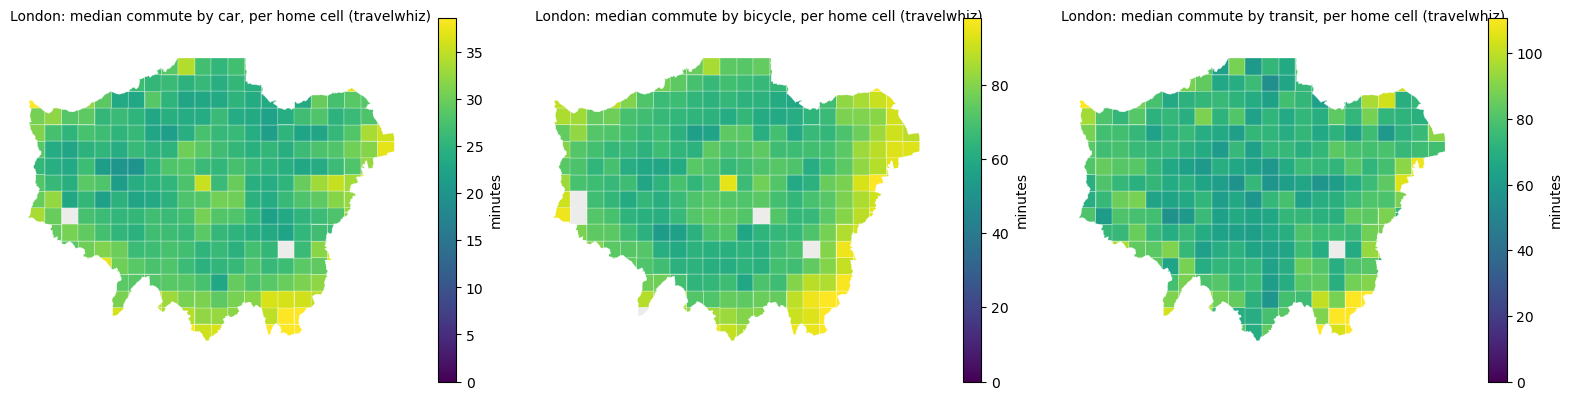

In [18]:
mapped = regions[["locations", "geometry"]].merge(per_cell, on="locations", how="left")
figure, axes = plt.subplots(ncols=3, figsize=(16, 5.5))
for axis, mode in zip(axes, MODES):
    column = f"{mode}_median_min"
    mapped.plot(column=column, ax=axis, cmap="viridis", vmin=0, vmax=np.nanpercentile(mapped[column], 98),
                edgecolor="white", linewidth=0.2, legend=True, legend_kwds={"shrink": 0.7, "label": "minutes"},
                missing_kwds={"color": "#ececea"})
    axis.set_title(f"{CITY}: median commute by {mode}, per home cell ({TRANSIT_SOURCE})", loc="left", fontsize=10)
    axis.set_axis_off()
figure.tight_layout()

### Check against the census: distance to work by borough

The maps above give the central cells some of the longest bicycle commutes. That can
only come from the flows themselves, since the routing is the same everywhere. The
2021 Census table TS058 (*Distance travelled to work*, NOMIS dataset NM_2075_1) gives,
for the residents of each London borough, the straight-line distance between home and
workplace in bands. The OD matrix gives straight-line distances between cell centres.
The two are compared band by band, London-wide and borough by borough.

Three things to keep in mind. The census counts people working mainly from home
separately; they are left out here, since the OD matrix has no such category, and in
2021 the census was taken during the pandemic. The grid cannot produce commutes under
2 km: the matrix has no intra-cell flows and adjacent cell centres are 2.6 km apart.
Each cell is assigned to the borough that contains its centre.

In [19]:
CENSUS_DIR = DATA / "census-2021"
CENSUS_DIR.mkdir(parents=True, exist_ok=True)
CENSUS_CSV = CENSUS_DIR / "ts058-distance-to-work-london-boroughs.csv"
BOROUGHS_GEOJSON = CENSUS_DIR / "london-boroughs-december-2021.geojson"
CENSUS_URL = ("https://www.nomisweb.co.uk/api/v01/dataset/NM_2075_1.data.csv"
              "?geography=TYPE154&measures=20100"
              "&select=GEOGRAPHY_CODE,GEOGRAPHY_NAME,C2021_TTWDIST_11,C2021_TTWDIST_11_NAME,OBS_VALUE")
BOROUGHS_URL = ("https://services1.arcgis.com/ESMARspQHYMw9BZ9/arcgis/rest/services/"
                "Local_Authority_Districts_December_2021_UK_BGC_2022/FeatureServer/0/query"
                "?where=LAD21CD%20like%20%27E09%25%27&outFields=LAD21CD,LAD21NM&f=geojson")
for url, path in [(CENSUS_URL, CENSUS_CSV), (BOROUGHS_URL, BOROUGHS_GEOJSON)]:
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    print(path.name, f"{path.stat().st_size / 1e3:.0f} kB")

census = pd.read_csv(CENSUS_CSV)
census = census.loc[census["GEOGRAPHY_CODE"].str.startswith("E09")]
census = census.pivot(index="GEOGRAPHY_NAME", columns="C2021_TTWDIST_11", values="OBS_VALUE")

# Census categories 1 to 8 are the distance bands; 0 is the total, 9 works from home, 10 no fixed place.
BANDS = {1: "under 2 km", 2: "2 to 5 km", 3: "5 to 10 km", 4: "10 to 20 km", 5: "20 to 30 km", 6: "30 to 40 km", 7: "40 to 60 km", 8: "60 km and over"}
BAND_EDGES = [0, 2, 5, 10, 20, 30, 40, 60, np.inf]
travelling = census[list(BANDS)].rename(columns=BANDS)
census_shares = travelling.div(travelling.sum(axis=1), axis=0)

print(f"{len(census)} boroughs; {census[0].sum():,.0f} residents in employment, "
      f"{census[9].sum() / census[0].sum():.0%} working mainly from home, {travelling.sum().sum():,.0f} travelling to a workplace")
census_shares.round(3)

ts058-distance-to-work-london-boroughs.csv 254 kB


london-boroughs-december-2021.geojson 250 kB
33 boroughs; 4,360,085 residents in employment, 42% working mainly from home, 1,908,057 travelling to a workplace


C2021_TTWDIST_11,under 2 km,2 to 5 km,5 to 10 km,10 to 20 km,20 to 30 km,30 to 40 km,40 to 60 km,60 km and over
GEOGRAPHY_NAME,,,,,,,,
Barking and Dagenham,0.120,0.222,0.208,0.313,0.087,0.020,0.011,0.019
Barnet,0.161,0.197,0.299,0.281,0.029,0.010,0.008,0.015
Bexley,0.139,0.231,0.240,0.269,0.078,0.018,0.010,0.015
Brent,0.169,0.282,0.291,0.201,0.025,0.008,0.007,0.018
Bromley,0.143,0.209,0.242,0.301,0.068,0.016,0.008,0.013
Camden,0.274,0.330,0.267,0.084,0.016,0.005,0.007,0.017
City of London,0.468,0.267,0.167,0.057,0.010,0.005,0.006,0.019
Croydon,0.156,0.222,0.266,0.271,0.052,0.011,0.009,0.013
Ealing,0.168,0.249,0.298,0.223,0.031,0.008,0.008,0.014


In [20]:
boroughs = gpd.read_file(BOROUGHS_GEOJSON).to_crs(regions.crs)[["LAD21NM", "geometry"]].rename(columns={"LAD21NM": "borough"})

# Each grid cell belongs to the borough that contains its centre.
cell_centres = gpd.GeoDataFrame({"locations": regions["locations"]}, geometry=regions.geometry.centroid, crs=regions.crs)
cell_borough = gpd.sjoin(cell_centres, boroughs, how="left", predicate="within")[["locations", "borough"]]
print(f"{cell_borough['borough'].notna().sum()} of {len(cell_borough)} cells fall in a borough; "
      f"{cell_borough['borough'].nunique()} boroughs with at least one cell")

# Straight-line distance of every OD pair between cell centres, in the census bands.
coordinates = dict(zip(regions["locations"], zip(metric.x, metric.y)))
od_distance = od[["from_id", "to_id", "flow"]].copy()
od_distance["km"] = [np.hypot(coordinates[a][0] - coordinates[b][0], coordinates[a][1] - coordinates[b][1]) / 1000
                     for a, b in zip(od_distance["from_id"], od_distance["to_id"])]
od_distance["band"] = pd.cut(od_distance["km"], bins=BAND_EDGES, right=False, labels=list(BANDS.values()))
od_distance = od_distance.merge(cell_borough, left_on="from_id", right_on="locations")
od_shares = od_distance.pivot_table(index="borough", columns="band", values="flow", aggfunc="sum", observed=False).fillna(0)
od_shares = od_shares.div(od_shares.sum(axis=1), axis=0)

# London-wide: share of commuters in each band, census and OD.
london = pd.DataFrame({
    "census_2021": travelling.sum() / travelling.sum().sum(),
    "worldcommuting_od": od_distance.groupby("band", observed=False)["flow"].sum() / od_distance["flow"].sum(),
})
london.round(3)

271 of 281 cells fall in a borough; 32 boroughs with at least one cell


,census_2021,worldcommuting_od
under 2 km,0.174,0.001
2 to 5 km,0.254,0.036
5 to 10 km,0.280,0.173
10 to 20 km,0.215,0.489
20 to 30 km,0.042,0.250
30 to 40 km,0.012,0.048
40 to 60 km,0.008,0.004
60 km and over,0.016,0.000


In [21]:
def share_under(shares, km):
    # Share of commutes shorter than km, summed from the band shares.
    return shares[[name for edge, name in zip(BAND_EDGES[1:], BANDS.values()) if edge <= km]].sum(axis=1)


city = boroughs.loc[boroughs["borough"] == "City of London", "geometry"].centroid.iloc[0]
by_borough = pd.DataFrame({
    "km_from_city": boroughs.set_index("borough").geometry.centroid.distance(city) / 1000,
    "cells": cell_borough.groupby("borough").size(),
    "census_under_5km": share_under(census_shares, 5),
    "od_under_5km": share_under(od_shares, 5),
    "census_under_10km": share_under(census_shares, 10),
    "od_under_10km": share_under(od_shares, 10),
    "census_20km_and_over": 1 - share_under(census_shares, 20),
    "od_20km_and_over": 1 - share_under(od_shares, 20),
}).dropna(subset=["cells"]).sort_values("km_from_city")
by_borough.round(2)

,km_from_city,cells,census_under_5km,od_under_5km,census_under_10km,od_under_10km,census_20km_and_over,od_20km_and_over
Tower Hamlets,3.94,1.0,0.55,0.00,0.84,0.12,0.05,0.21
Islington,3.95,2.0,0.61,0.00,0.87,0.17,0.04,0.24
Hackney,4.62,3.0,0.57,0.00,0.86,0.13,0.04,0.25
Westminster,4.80,3.0,0.68,0.01,0.88,0.16,0.05,0.23
Southwark,4.80,5.0,0.53,0.03,0.85,0.19,0.05,0.20
Camden,5.73,2.0,0.60,0.02,0.87,0.21,0.05,0.28
Lambeth,7.11,3.0,0.44,0.01,0.83,0.13,0.05,0.23
Kensington and Chelsea,7.14,3.0,0.62,0.01,0.88,0.16,0.04,0.21
Haringey,8.47,5.0,0.36,0.01,0.74,0.23,0.06,0.30
Lewisham,8.95,5.0,0.38,0.03,0.73,0.22,0.05,0.22


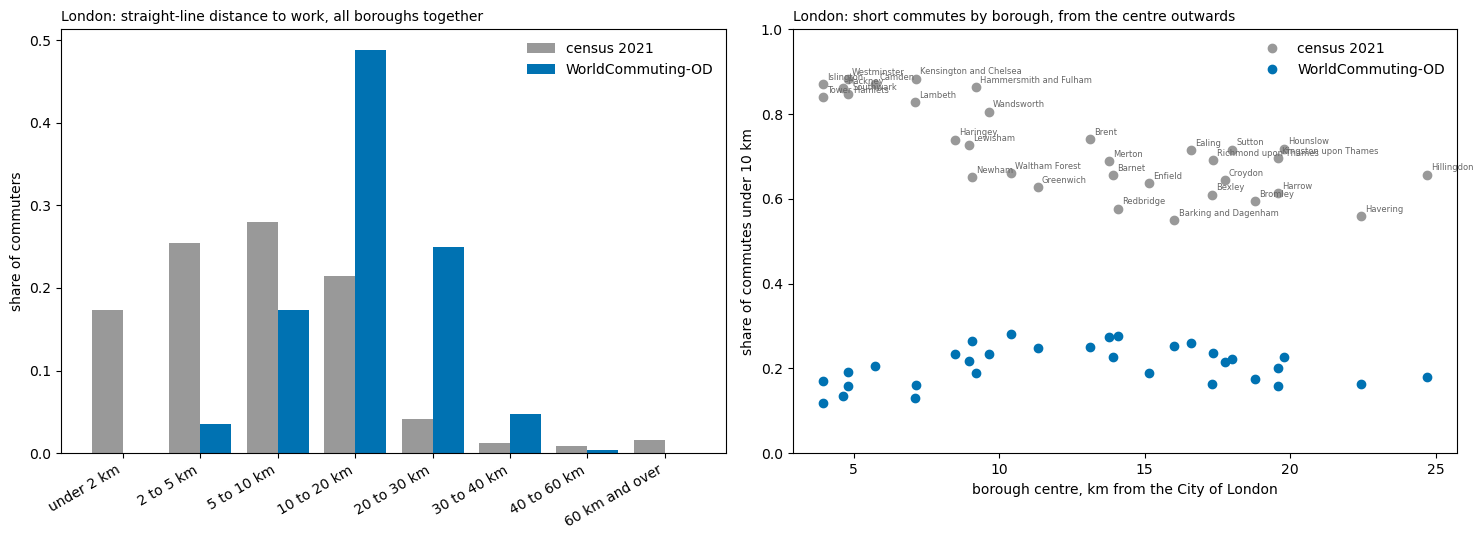

In [22]:
figure, axes = plt.subplots(ncols=2, figsize=(15, 5.5))
positions = np.arange(len(BANDS))
axes[0].bar(positions - 0.2, london["census_2021"], width=0.4, color="#999999", label="census 2021")
axes[0].bar(positions + 0.2, london["worldcommuting_od"], width=0.4, color="#0072B2", label="WorldCommuting-OD")
axes[0].set_xticks(positions, list(BANDS.values()), rotation=30, ha="right")
axes[0].set_ylabel("share of commuters")
axes[0].legend(frameon=False)
axes[0].set_title(f"{CITY}: straight-line distance to work, all boroughs together", loc="left", fontsize=10)

axes[1].plot(by_borough["km_from_city"], by_borough["census_under_10km"], "o", color="#999999", label="census 2021")
axes[1].plot(by_borough["km_from_city"], by_borough["od_under_10km"], "o", color="#0072B2", label="WorldCommuting-OD")
for name, row in by_borough.iterrows():
    axes[1].annotate(name, (row["km_from_city"], row["census_under_10km"]), fontsize=6, xytext=(3, 3), textcoords="offset points", color="#666666")
axes[1].set_xlabel("borough centre, km from the City of London")
axes[1].set_ylabel("share of commutes under 10 km")
axes[1].set_ylim(0, 1)
axes[1].legend(frameon=False)
axes[1].set_title(f"{CITY}: short commutes by borough, from the centre outwards", loc="left", fontsize=10)
figure.tight_layout()

## 8. Comparison with 04.2

The 04.2 results are read from scratch (`REFERENCE`) and set against this notebook's,
pair by pair. Car and bicycle do not depend on the timetable and are checked to be
equal, which confirms that both notebooks routed between the same points. The transit
comparison then isolates the effect of the feeds. The labels below are `bods+gbtransit`
for the 04.2 sources and `travelwhiz` for this notebook.

In [23]:
LABELS = {"reference": "bods+gbtransit", "travelwhiz": TRANSIT_SOURCE}

# The two networks side by side.
reference_network = TransportNetwork.load(REFERENCE_ARTIFACT)
networks = pd.DataFrame({
    LABELS["reference"]: {"stops": reference_network.stop_count, "trips": reference_network.trip_count, "artifact_MB": REFERENCE_ARTIFACT.stat().st_size / 1e6},
    LABELS["travelwhiz"]: {"stops": transit_network.stop_count, "trips": transit_network.trip_count, "artifact_MB": TRANSIT_ARTIFACT.stat().st_size / 1e6},
})
networks.round(0).astype(int)

loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

,bods+gbtransit,travelwhiz
stops,34943,73094
trips,911209,1031811
artifact_MB,1602,2322


In [24]:
# The test trips: transit minutes with each source, and the difference.
reference_times = pd.read_parquet(REFERENCE / "test_trips_times.parquet")
test = times[["from_id", "to_id", "flow", "straight_km", "car_min", "bicycle_min"]].copy()
test[f"transit_min_{LABELS['reference']}"] = reference_times["transit_min"].to_numpy()
test[f"transit_min_{LABELS['travelwhiz']}"] = times["transit_min"].to_numpy()
test["difference_min"] = test[f"transit_min_{LABELS['travelwhiz']}"] - test[f"transit_min_{LABELS['reference']}"]

same_points = np.allclose(reference_times[["car_min", "bicycle_min"]].fillna(-1), times[["car_min", "bicycle_min"]].fillna(-1))
print("car and bicycle times identical to 04.2:", same_points)
test.round(1)

car and bicycle times identical to 04.2: True


,from_id,to_id,flow,straight_km,car_min,bicycle_min,transit_min_bods+gbtransit,transit_min_travelwhiz,difference_min
0,14-14,11-10,3320.0,12.3,20.2,55.4,50.9,50.9,0.0
1,6-3,8-9,2918.0,16.1,28.3,81.9,87.8,87.7,-0.0
2,1-8,8-9,2727.0,18.3,27.9,NaN,69.4,57.7,-11.8
3,14-14,12-10,2687.0,10.9,17.7,53.2,45.8,45.8,0.0
4,6-3,10-6,2626.0,13.0,24.2,65.4,74.0,73.6,-0.5
5,14-14,10-10,2616.0,14.0,26.0,61.7,62.4,62.4,0.0
6,14-14,10-11,2473.0,12.3,23.6,58.0,58.8,58.8,0.0
7,6-3,9-8,2460.0,14.9,23.4,76.6,83.7,83.7,0.0
8,13-4,12-8,2420.0,10.7,20.3,53.7,96.6,86.5,-10.1
9,13-4,11-9,2340.0,13.9,24.4,62.7,73.3,73.3,0.0


In [25]:
# The whole city: every OD pair with a flow, transit minutes from both sources.
reference_od = pd.read_parquet(REFERENCE / "od_times.parquet")
both = od[["from_id", "to_id", "flow", "car_min", "bicycle_min", "transit_min"]].merge(
    reference_od[["from_id", "to_id", "car_min", "bicycle_min", "transit_min"]],
    on=["from_id", "to_id"], suffixes=(f"_{LABELS['travelwhiz']}", f"_{LABELS['reference']}"))
print(f"{len(both):,} OD pairs in both notebooks, {both['flow'].sum():,.0f} commuters")
print("car and bicycle identical to 04.2:",
      np.allclose(both[f"car_min_{LABELS['reference']}"].fillna(-1), both[f"car_min_{LABELS['travelwhiz']}"].fillna(-1))
      and np.allclose(both[f"bicycle_min_{LABELS['reference']}"].fillna(-1), both[f"bicycle_min_{LABELS['travelwhiz']}"].fillna(-1)))

transit_columns = {label: f"transit_min_{label}" for label in LABELS.values()}
comparison = {}
for label, column in transit_columns.items():
    reached = both[column].notna()
    minutes = both.loc[reached, column].to_numpy()
    weights = both.loc[reached, "flow"].to_numpy()
    comparison[label] = {
        "share_of_commuters_reached": weights.sum() / both["flow"].sum(),
        "mean_min_flow_weighted": np.average(minutes, weights=weights),
        "median_min_flow_weighted": weighted_median(minutes, weights),
    }
pd.DataFrame(comparison).round(2)

73,162 OD pairs in both notebooks, 8,324,159 commuters
car and bicycle identical to 04.2: True


,bods+gbtransit,travelwhiz
share_of_commuters_reached,0.99,0.99
mean_min_flow_weighted,75.30,73.61
median_min_flow_weighted,74.43,72.80


72,619 pairs reached by both; 8,252,190 commuters
flow-weighted mean difference (travelwhiz minus bods+gbtransit): -1.7 min; median 0.0 min
share of commuters by difference:


,share_of_commuters
difference_min,
faster by 15+ min,0.035
faster by 5 to 15,0.110
within 5 min,0.826
slower by 5 to 15,0.028
slower by 15+ min,0.002


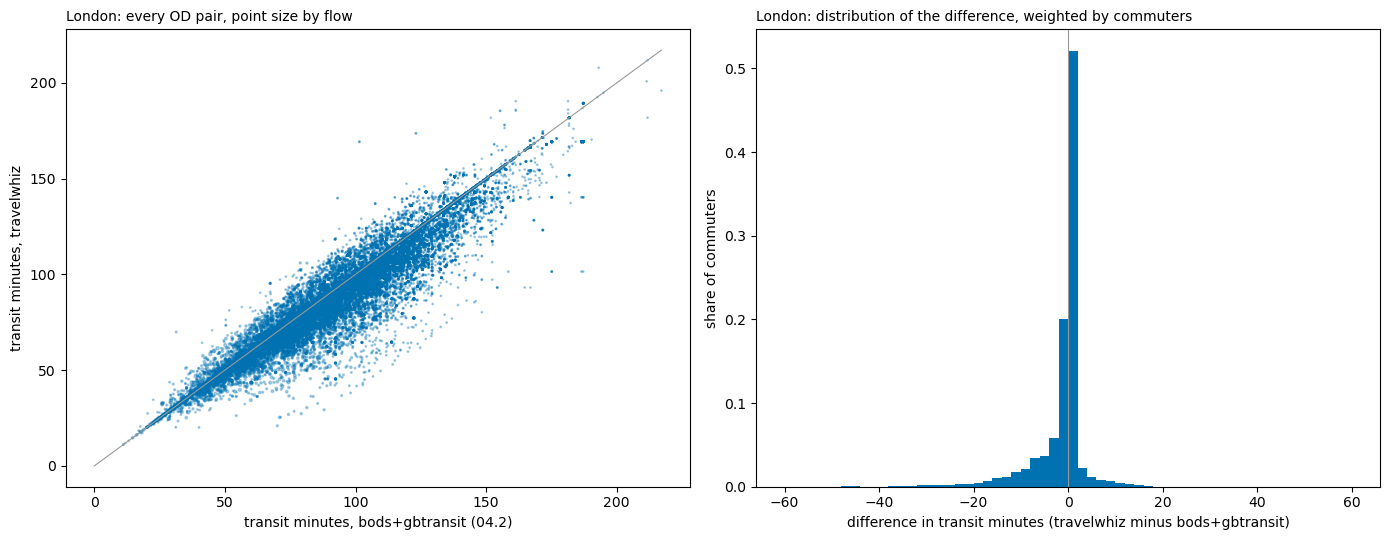

In [26]:
# Pair-by-pair difference in transit minutes, weighted by commuters.
paired = both.dropna(subset=list(transit_columns.values())).copy()
paired["difference_min"] = paired[transit_columns[LABELS["travelwhiz"]]] - paired[transit_columns[LABELS["reference"]]]
weights = paired["flow"].to_numpy()
difference = paired["difference_min"].to_numpy()
print(f"{len(paired):,} pairs reached by both; {weights.sum():,.0f} commuters")
print(f"flow-weighted mean difference ({LABELS['travelwhiz']} minus {LABELS['reference']}): {np.average(difference, weights=weights):.1f} min; "
      f"median {weighted_median(difference, weights):.1f} min")
print("share of commuters by difference:")
bins = [-np.inf, -15, -5, 5, 15, np.inf]
labels = ["faster by 15+ min", "faster by 5 to 15", "within 5 min", "slower by 5 to 15", "slower by 15+ min"]
share = paired.groupby(pd.cut(paired["difference_min"], bins=bins, labels=labels), observed=False)["flow"].sum() / weights.sum()
display(share.round(3).to_frame("share_of_commuters"))

figure, axes = plt.subplots(ncols=2, figsize=(14, 5.5))
axes[0].scatter(paired[transit_columns[LABELS["reference"]]], paired[transit_columns[LABELS["travelwhiz"]]],
                s=1 + 20 * paired["flow"] / paired["flow"].max(), alpha=0.3, color="#0072B2")
limit = max(paired[list(transit_columns.values())].max())
axes[0].plot([0, limit], [0, limit], color="#999999", linewidth=0.8)
axes[0].set_xlabel(f"transit minutes, {LABELS['reference']} (04.2)")
axes[0].set_ylabel(f"transit minutes, {LABELS['travelwhiz']}")
axes[0].set_title(f"{CITY}: every OD pair, point size by flow", loc="left", fontsize=10)
axes[1].hist(difference, bins=np.arange(-60, 61, 2), weights=weights / weights.sum(), color="#0072B2")
axes[1].axvline(0, color="#999999", linewidth=0.8)
axes[1].set_xlabel(f"difference in transit minutes ({LABELS['travelwhiz']} minus {LABELS['reference']})")
axes[1].set_ylabel("share of commuters")
axes[1].set_title(f"{CITY}: distribution of the difference, weighted by commuters", loc="left", fontsize=10)
figure.tight_layout()

difference of the per-cell medians (min):


,count,mean,std,min,10%,50%,90%,max
difference_min,278.0,-1.5,3.8,-30.8,-4.5,-0.9,0.6,13.8


cells with the largest differences:


,locations,residents,transit_median_min_travelwhiz,transit_median_min_bods+gbtransit,difference_min
41,11-15,30659.0,55.4,86.2,-30.8
123,16-5,31349.0,67.8,84.4,-16.6
98,15-0,2241.0,103.6,118.4,-14.7
175,20-9,1612.0,101.0,87.2,13.8
25,10-16,27880.0,59.5,73.3,-13.8
40,11-14,28279.0,63.1,75.8,-12.8
30,10-6,34844.0,62.3,75.0,-12.7
136,17-5,3869.0,93.4,105.7,-12.3
42,11-16,34030.0,73.6,85.7,-12.1
160,19-9,723.0,105.2,93.1,12.1


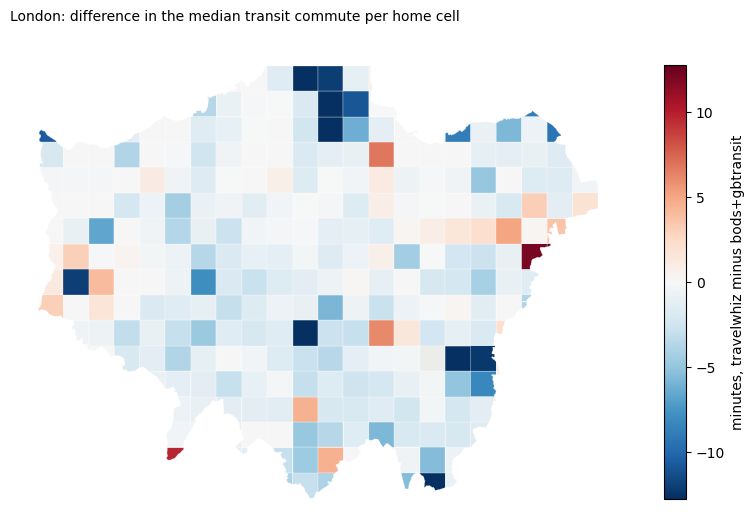

In [27]:
# Median transit time per home cell with each source, and the difference on the map.
reference_per_cell = pd.read_csv(REFERENCE / "median_minutes_by_home_cell.csv")
cell_comparison = per_cell[["locations", "residents", "transit_median_min"]].merge(
    reference_per_cell[["locations", "transit_median_min"]], on="locations",
    suffixes=(f"_{LABELS['travelwhiz']}", f"_{LABELS['reference']}"))
cell_comparison["difference_min"] = (cell_comparison[f"transit_median_min_{LABELS['travelwhiz']}"]
                                     - cell_comparison[f"transit_median_min_{LABELS['reference']}"])
print("difference of the per-cell medians (min):")
display(cell_comparison["difference_min"].describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame().T)
print("cells with the largest differences:")
display(cell_comparison.reindex(cell_comparison["difference_min"].abs().sort_values(ascending=False).index).head(10).round(1))

mapped = regions[["locations", "geometry"]].merge(cell_comparison, on="locations", how="left")
figure, axis = plt.subplots(figsize=(8, 6.5))
span = np.nanpercentile(mapped["difference_min"].abs(), 98)
mapped.plot(column="difference_min", ax=axis, cmap="RdBu_r", vmin=-span, vmax=span, edgecolor="white", linewidth=0.2,
            legend=True, legend_kwds={"shrink": 0.7, "label": f"minutes, {LABELS['travelwhiz']} minus {LABELS['reference']}"},
            missing_kwds={"color": "#ececea"})
axis.set_title(f"{CITY}: difference in the median transit commute per home cell", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()